In [1]:
import sys, time
sys.path.append("..")
import numpy as np
from extraction.extract import extract_video
from features.pipeline import process_array

start = time.time()
arr = extract_video("../data/test_videos/me.mp4", "../models/holistic_landmarker.task")
elapsed = time.time() - start
print(arr.shape, arr.dtype, f"| {elapsed:.1f}s total, {elapsed / max(len(arr), 1) * 1000:.0f} ms per frame")

for name, start_row, n in [("face", 0, 468), ("left_hand", 468, 21), ("pose", 489, 33), ("right_hand", 522, 21)]:
    present = (~np.isnan(arr[:, start_row, 0])).sum()
    print(f"{name:>10}: present in {present}/{len(arr)} frames")

(166, 543, 3) float32 | 5.8s total, 35 ms per frame
      face: present in 166/166 frames
 left_hand: present in 0/166 frames
      pose: present in 166/166 frames
right_hand: present in 134/166 frames


In [2]:
feats = process_array(arr)
print(feats.shape, "| any NaN:", np.isnan(feats).any(),
      "| dom hand frames:", int(feats[:, -2].sum()), "| nondom:", int(feats[:, -1].sum()))

(166, 320) | any NaN: False | dom hand frames: 134 | nondom: 0


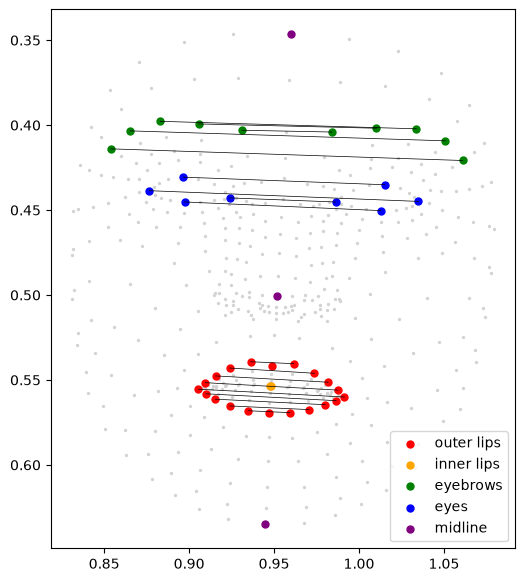

In [3]:
import matplotlib.pyplot as plt
from features.landmarks import FACE_START, LIPS_OUTER, LIPS_INNER, EYEBROWS, EYES, MIDLINE, FACE_PAIRS

face = arr[0, FACE_START:FACE_START + 468]

plt.figure(figsize=(7, 7))
plt.scatter(face[:, 0], face[:, 1], s=2, c="lightgrey")
groups = [("outer lips", LIPS_OUTER, "red"), ("inner lips", LIPS_INNER, "orange"),
          ("eyebrows", EYEBROWS, "green"), ("eyes", EYES, "blue"), ("midline", MIDLINE, "purple")]
for name, idx, colour in groups:
    plt.scatter(face[idx, 0], face[idx, 1], s=25, c=colour, label=name)
for p, q in FACE_PAIRS:
    plt.plot([face[p, 0], face[q, 0]], [face[p, 1], face[q, 1]], c="black", lw=0.5)
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.legend()
plt.savefig("../docs/figures/face_indices_own_video.png", dpi=150, bbox_inches="tight")
plt.show()